# 02 Exploratory data analysis

What the cleaned Google Play reviews of Tabby and Tamara look like before any modeling:
volume, ratings, language, where reviewers are, length, developer replies, and the words
that separate negative from positive reviews.

All logic lives in `src/clean/` and `src/analysis/`; this notebook only calls it.
Build the clean dataset first:
```
python -m src.clean.pipeline
```
Figures are saved to `reports/figures/eda_*.png`. Numbers in the text are from the
collection of 2026-11-15. Times are in UTC.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

from src.analysis import eda as E
from src.analysis.plots import (
    VIZ, app_color, app_name, caption, grouped_bars, lines_by_app, save, setup_style, terms_panel,
)
from src.config import get_path, set_seed

set_seed()
setup_style()
pd.set_option("display.width", 160)

df_all = E.load_clean(source=None)
df = df_all[df_all["source"] == "google_play"].reset_index(drop=True)          # main dataset
df_rss = df_all[df_all["source"] == "app_store_rss"].reset_index(drop=True)    # App Store, recent reviews
SOURCE_NOTE = "Source: Google Play reviews (Arabic and English queries, all countries), collected 2026-11-15."
df.shape

(183341, 27)

## 1. Cleaning summary

The pipeline removes very little: 2 double submissions, 73 reviews written only in other
scripts (mostly Bengali, such as "ভালো", and Malayalam), and 103 with no usable content
(punctuation, digits or a single letter). Repeated *text* is not treated as a duplicate:
thousands of different people wrote "جيد" or "👍", and each is a real opinion. When a later
collection run reads a review again (to pick up edits and new replies), only the latest
copy is kept (`older_copy`).

In [2]:
pd.read_csv(get_path("cleaning_log"))

,step,reason,removed,rows_after
0,loaded,all raw files,0,184501
1,older_copy,earlier copy of a review collected again (late...,0,184501
2,double_submission,"same source, app, text, rating and timestamp",2,184499
3,empty,empty text,0,184499
4,other_script,only letters of scripts other than Arabic and ...,73,184426
5,no_content,fewer than 2 Arabic/Latin letters and no emoji,103,184323


## 2. Overview

Ratings are very high for both apps on Google Play, and the App Store RSS sample
(recent reviews only, Saudi storefront) is much more negative. That gap is a reminder that
Google Play averages are inflated by very short 5-star reviews (section 6).

In [3]:
E.overview(df)

,reviews,first_month,last_month,mean_rating,share_negative,share_arabic,reply_rate
app,,,,,,,
tabby,119338,2020-10,2026-11,4.6,0.077,0.455,0.556
tamara,64003,2021-04,2026-11,4.65,0.065,0.597,0.108


In [4]:
E.overview(df_rss).drop(columns="reply_rate")  # RSS feed has no reply data

,reviews,first_month,last_month,mean_rating,share_negative,share_arabic
app,,,,,,
tabby,494,2026-06,2026-11,3.7,0.314,0.650
tamara,488,2025-10,2026-11,3.13,0.457,0.766


## 3. Language

Language was detected from the text, not taken from the store's language bucket.
The `en` bucket turned out to be mostly English after all (95%), but each bucket
still holds about 2,000 reviews in the other language. **Arabizi** (Arabic in Latin
letters, like "7lw") does not occur. Loan phrases that are common in English reviews
("mashallah", "inshallah") are excluded from the Arabizi word list so that they do not
cause false positives.

Tabby's reviews are about half English and Tamara's are 60% Arabic.

In [5]:
E.language_vs_query(df)

lang,arabic,emoji_only,english,mixed,All
lang_query,,,,,
ar,90565,2806,2653,65,96089
en,1921,2014,83270,47,87252
All,92486,4820,85923,112,183341


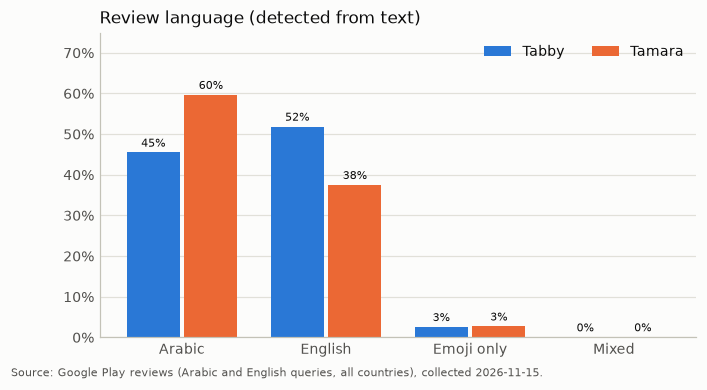

In [6]:
mix = E.language_mix(df)
fig, ax = plt.subplots(figsize=(7, 3.6))
grouped_bars(ax, mix, fmt="{:.0%}", xlabels=["Arabic", "English", "Emoji only", "Mixed"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.75)
ax.set_title("Review language (detected from text)")
caption(fig, SOURCE_NOTE)
save(fig, "eda_language_mix");

## 4. Where reviewers are

Google Play returns the same reviews whatever store country is requested, so these reviews
are not limited to Saudi Arabia: both apps are used in other Gulf countries too. Reviews
rarely say where the reviewer is, but 0.8% name a country, city, currency or national
service (for example "riyal", "AED", "Dubai", "نفاذ"). Among those, **Arabic reviews point to
Saudi Arabia 84% of the time** (UAE 13%), while **English reviews point to the UAE 65% of the
time** (Saudi Arabia 34%). The share is small, so this indicates where reviewers are rather
than measuring it.

The App Store sample comes from the Saudi storefront only. Over the same dates it is much
more Arabic than Google Play (Tabby 67% vs. 41%, Tamara 78% vs. 60%), which fits the same
picture. iPhone and Android users can differ, so this supports the finding rather than
proving it. The events analysis therefore treats Arabic reviews as the closest stand-in for
Saudi users.

In [7]:
E.country_mentions(df, by="lang")

,reviews,with_marker,marker_share,saudi_arabia,uae,kuwait
lang,,,,,,
arabic,92486,675,0.0073,0.844,0.130,0.046
emoji_only,4820,0,0.0000,NaN,NaN,NaN
english,85923,837,0.0097,0.338,0.655,0.030
mixed,112,4,0.0357,0.500,0.500,0.000


In [8]:
E.source_language_share(df_all)

since  reviews  arabic_share
app    source                                          
tabby  app_store_rss  2026-06-11      478         0.672
       google_play    2026-06-11    14605         0.413
tamara app_store_rss  2025-10-26      478         0.782
       google_play    2025-10-26     9781         0.597

## 5. Volume and sentiment over time

Reviews are split by stars: 1–2 negative, 4–5 positive (3 = neutral, not shown).
**Counts**, not shares, are plotted so that a change in how many happy users review
cannot hide or fake a change in complaints. The incomplete current month is left out.

Two things stand out:

1. **Tamara, February 2026:** positive reviews fall about 90% (from about 2,200 a month to
   about 190), while negative reviews fall much less, about 37% (from 114 to 72 a month). So
   Tamara's average rating drops from about 4.7 to about 3.9 mainly because of **who is
   reviewing**, not because more people complain. A share-based sentiment index would show
   a crash for Tamara that the complaint counts don't support, so the counts must be shown
   next to any such index.
2. **Tabby, July–August 2026:** negative reviews jump to 370 and 561 a month (137–239 in the
   other months from October 2025 to October 2026). Most of Tabby's reviews that mention a blank
   white screen fall in these two months (below).

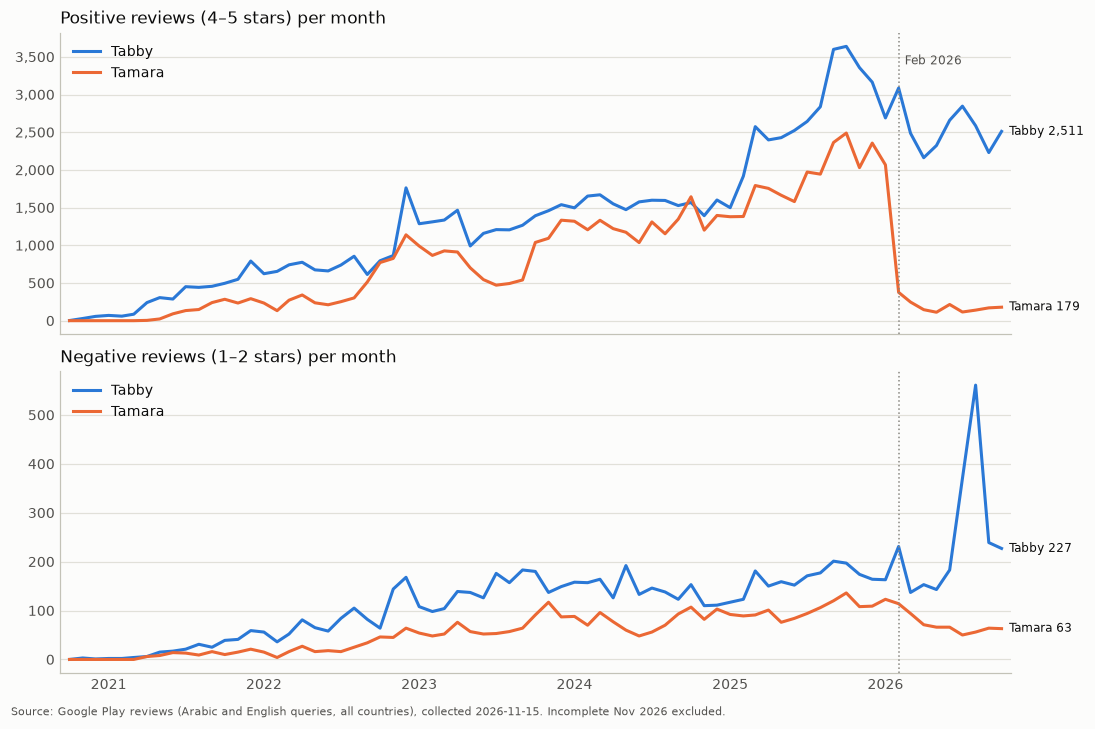

In [9]:
last_full = df["month"].max()  # partial month, excluded
pos = E.monthly_by_sentiment(df, "positive").loc[lambda t: t.index < last_full]
neg = E.monthly_by_sentiment(df, "negative").loc[lambda t: t.index < last_full]

fig, axes = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True)
lines_by_app(axes[0], pos)
axes[0].set_title("Positive reviews (4–5 stars) per month")
lines_by_app(axes[1], neg)
axes[1].set_title("Negative reviews (1–2 stars) per month")
for ax in axes:
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.axvline(pd.Timestamp("2026-02-01"), color=VIZ["reference_line"], linestyle=":", linewidth=1)
axes[0].annotate("Feb 2026", (pd.Timestamp("2026-02-01"), 3400),
                 xytext=(4, 0), textcoords="offset points", ha="left", fontsize=8, color=VIZ["muted"])
caption(fig, SOURCE_NOTE + " Incomplete Nov 2026 excluded.")
fig.tight_layout(rect=(0, 0.02, 1, 1))
save(fig, "eda_reviews_by_sentiment");

In [10]:
# Tamara: monthly averages before and after February 2026
t = df[(df["app"] == "tamara") & (df["month"] >= "2025-07-01") & (df["month"] < last_full)]
t.groupby(t["month"] >= "2026-02-01").agg(
    months=("month", "nunique"),
    reviews_per_month=("review_id", lambda s: round(len(s) / t.loc[s.index, "month"].nunique())),
    mean_rating=("rating", "mean"),
    positives_per_month=("sentiment", lambda s: round((s == "positive").sum() / t.loc[s.index, "month"].nunique())),
    negatives_per_month=("sentiment", lambda s: round((s == "negative").sum() / t.loc[s.index, "month"].nunique())),
).rename(index={False: "Jul 2025 - Jan 2026", True: "Feb 2026 - Oct 2026"}).round(2)

,months,reviews_per_month,mean_rating,positives_per_month,negatives_per_month
month,,,,,
Jul 2025 - Jan 2026,7,2335,4.72,2175,114
Feb 2026 - Oct 2026,9,268,3.86,189,72


**What changed at Tamara?** The break lines up with app version 6.0. From December 2025
to mid-April 2026, versions 5.8.1–5.9.2 each received 858–1,688 reviews, about 95% positive,
while each 6.x version received 25–128 reviews, 50–80% positive. Version 6.0.2 first
appears on 22 January 2026. Reviews without an app version stay at 85–115 a month from
December to March, so they do not show the drop. Google search interest for "تمارا" in
Saudi Arabia rises from January to March (84, 89, 95), and Tabby shows no similar drop.
Together this **suggests** that version 6.0 stopped asking satisfied users for a rating,
rather than that users turned away from the app; it is not confirmed.

In [11]:
E.version_summary(df, "tamara", "2025-12-01", "2026-04-15")

,reviews,positive_share,negative,first,last
app_version,,,,,
5.3.0,25,0.96,0,2025-12-01,2026-02-13
5.4.1,64,0.95,2,2025-12-01,2026-04-11
5.5.0,17,0.88,0,2025-12-01,2026-01-04
5.6.0,26,0.88,1,2025-12-01,2026-02-09
5.7.0,274,0.96,7,2025-12-01,2026-04-06
5.8.1,1688,0.94,68,2025-12-01,2026-04-10
5.9.0,1619,0.95,65,2025-12-21,2026-04-10
5.9.2,858,0.95,25,2026-01-14,2026-02-26
6.0.2,55,0.64,18,2026-01-22,2026-03-05


In [12]:
# Tamara reviews without an app version, and Google search interest (Saudi Arabia)
window = df[(df["app"] == "tamara") & (df["month"] >= "2025-11-01") & (df["month"] <= "2026-04-01")]
no_version = window.groupby("month")["app_version"].apply(lambda s: int(s.isna().sum()))
trends = pd.read_parquet(get_path("trends_time")).set_index("month")["tamara"]
pd.DataFrame({"reviews_without_version": no_version, "search_interest": trends.reindex(no_version.index)})

,reviews_without_version,search_interest
month,,
2025-11-01,81,77.0
2025-12-01,98,78.0
2026-01-01,114,84.0
2026-02-01,99,89.0
2026-03-01,85,95.0
2026-04-01,42,81.0


In [13]:
# Tabby: reviews mentioning a blank white screen, by month
white = df[(df["app"] == "tabby") & E.mentions(df, "white_screen")]
by_month = white.groupby(white["month"].dt.strftime("%Y-%m")).size()
print(f"{len(white)} mentions; {by_month.loc[['2026-07', '2026-08']].sum() / len(white):.0%} in Jul-Aug 2026")
by_month.loc["2026-03":]

278 mentions; 85% in Jul-Aug 2026


month
2026-06      1
2026-07     82
2026-08    153
2026-09     15
2026-10      7
2026-11      3
dtype: int64

## 6. Ratings and review length

About 84% of reviews are 5 stars and only 6–7% are 1 star. Positive reviews are tiny:
the median 4–5 star review is **2 words** ("ممتاز", "good app"), while the median 1-star
review is 12–13 words. For modeling this means:
- classes are very imbalanced, so report **macro-F1**, not accuracy;
- most of the actual text (and most of the signal about *what* goes wrong) sits in the
  negative reviews.

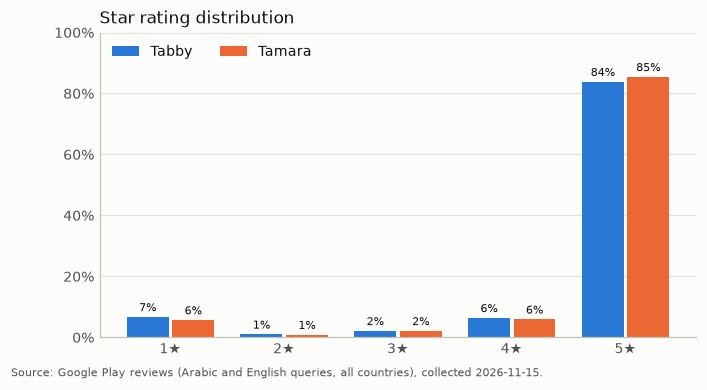

In [14]:
dist = E.rating_distribution(df)
fig, ax = plt.subplots(figsize=(7, 3.6))
grouped_bars(ax, dist, fmt="{:.0%}", xlabels=[f"{s}★" for s in dist.index], legend_loc="upper left")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0, 1)
ax.set_title("Star rating distribution")
caption(fig, SOURCE_NOTE)
save(fig, "eda_rating_distribution");

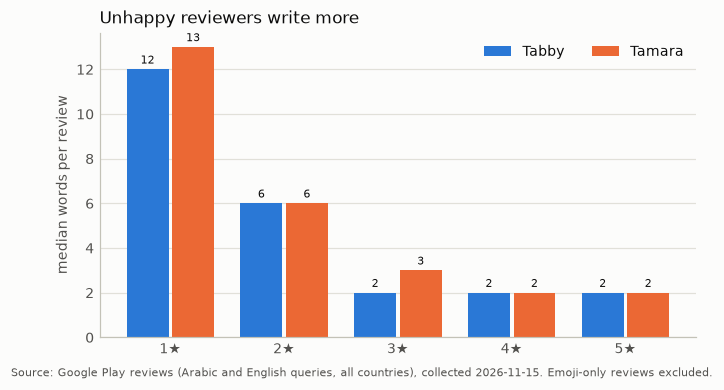

In [15]:
length = E.length_by_rating(df)
fig, ax = plt.subplots(figsize=(7, 3.6))
grouped_bars(ax, length, fmt="{:.0f}", xlabels=[f"{s}★" for s in length.index])
ax.set_ylabel("median words per review")
ax.set_title("Unhappy reviewers write more")
caption(fig, SOURCE_NOTE + " Emoji-only reviews excluded.")
save(fig, "eda_length_by_rating");

## 7. Developer replies

The headline "Tabby replies to 56% of reviews, Tamara to 11%" is misleading on its own.
Broken down by rating, **both apps reply to about 87–92% of 1–2 star reviews**. The gap
comes from positive reviews: Tabby replies to about half of its 4–5 star reviews, Tamara to
3–6%. Tabby's reply rate also changed over time, from under 10% before 2024 to 98% in 2026,
which suggests a change in policy (likely automated or templated replies to positive
reviews). Tamara's higher rate in 2026 (27%) mostly reflects the larger share of negative
reviews after February: in 2026 it replied to 99% of 1–2 star and 10% of 4–5 star reviews.
Tabby's 2020 point rests on 92 reviews.

**Response time** has to be compared like for like, because the apps reply to different
kinds of reviews and their habits changed over the years. Pooled over all ratings and
years, the median is 0.8 hours for Tamara and 22 hours for Tabby. For 1–2 star reviews in
2025–26 the gap is similar (Tamara 0.6 hours, Tabby 20 hours), but in 2022–23 it was the
reverse (Tabby 2–5 hours, Tamara 36–39 hours). Very fast replies may be automated.

Review dates are the latest edit of a review and reply dates the latest edit of a reply.
A response time can therefore be longer than the time to the first reply (the reply was
edited later) or shorter (the review was edited before the reply). Replies dated before the
review (1.3% for Tabby, 2.7% for Tamara) are excluded.

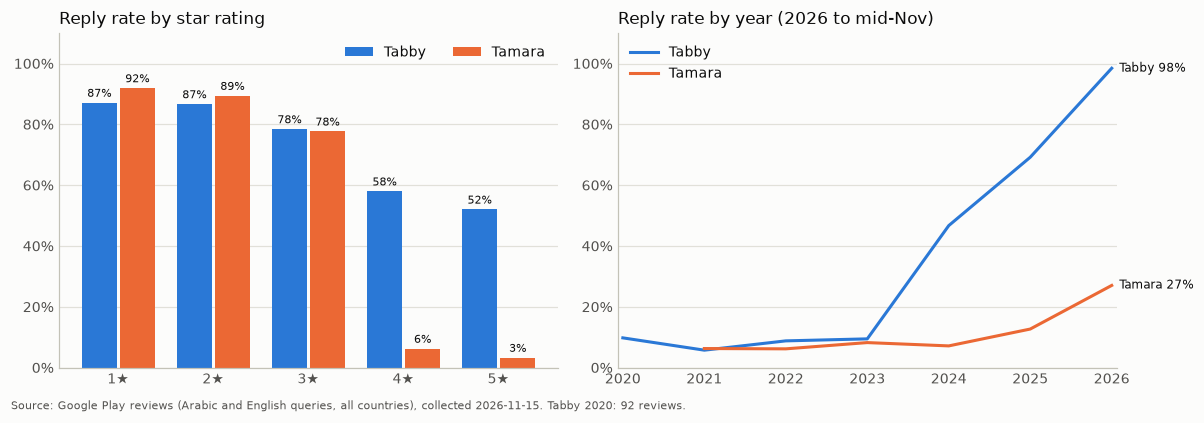

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
by_rating = E.reply_by_rating(df).astype(float)
grouped_bars(axes[0], by_rating, fmt="{:.0%}", xlabels=[f"{s}★" for s in by_rating.index])
axes[0].set_title("Reply rate by star rating")
axes[0].set_ylim(0, 1.1)
by_year = E.reply_by_year(df).astype(float)
lines_by_app(axes[1], by_year, fmt="{:.0%}")
axes[1].set_title("Reply rate by year (2026 to mid-Nov)")
axes[1].set_ylim(0, 1.1)
axes[1].set_xticks(by_year.index)
for ax in axes:
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
n_2020 = int(((df["app"] == "tabby") & (df["year"] == 2020)).sum())
caption(fig, SOURCE_NOTE + f" Tabby 2020: {n_2020} reviews.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "eda_developer_replies");

In [17]:
E.reply_time(df)  # all ratings and years

,replied,excluded,median_h,p75_h,p90_h,within_24h,excluded_share
app,,,,,,,
tabby,66408,890,22.4,99.5,379.6,0.515,0.013
tamara,6910,187,0.8,29.4,47.5,0.648,0.027


In [18]:
# 1-2 star reviews only, by year
negative = df[df["sentiment"] == "negative"]
E.reply_time(negative, by=["year", "app"])

replied  excluded  median_h  p75_h   p90_h  within_24h  excluded_share
year app                                                                           
2020 tabby         4         0     249.9  259.9   260.8       0.000           0.000
2021 tabby       214        12      55.0   97.0   260.2       0.233           0.056
     tamara       80         4      81.3  257.2   695.7       0.329           0.050
2022 tabby       799        14       5.2   16.5    71.4       0.803           0.018
     tamara      269        14      35.8   62.6   166.4       0.302           0.052
2023 tabby      1095        29       2.3  382.5  1233.3       0.653           0.026
     tamara      682        24      38.8   69.2   225.8       0.002           0.035
2024 tabby      1433        59      55.3  234.8   817.4       0.377           0.041
     tamara      859        36      34.9   42.8    61.4       0.000           0.042
2025 tabby      1904        85      27.8   70.0   134.2       0.468           0.045
     tamara     1168         2       0.6    0.8     2.4       0.960           0.002
2026 tabby      2516       131      16.5   45.5    91.7       0.606           0.052
     tamara      778         2       0.6    0.9     2.7       0.991           0.003

In [19]:
# 1-2 star reviews, 2025-2026
E.reply_time(negative[negative["year"] >= 2025])

,replied,excluded,median_h,p75_h,p90_h,within_24h,excluded_share
app,,,,,,,
tabby,4420,216,20.4,55.5,110.1,0.546,0.049
tamara,1946,4,0.6,0.8,2.6,0.972,0.002


## 8. What separates negative from positive reviews

Words and two-word phrases are ranked by the **weighted log-odds ratio with an informative
Dirichlet prior** (Monroe, Colaresi & Quinn, 2008), counting the reviews that contain each
phrase. The prior is weak, so the ranking is close to a smoothed log-odds ratio with a
z-score. It shows how **distinctive** a phrase is of negative or positive reviews, not how
**often** it is used. Only phrases in at least 30 reviews and with z ≥ 2 are shown. Arabic
and English reviews are ranked separately.

Themes in negative reviews (to be measured properly by topic modeling):
- **Customer service** is the top negative phrase for both apps in both languages
  ("خدمه العملاء", "customer service").
- **Tabby:** a blank white screen after app updates ("صفحه بيضاء" / "شاشه بيضاء"), blocked
  cards, late fees.
- **Tamara:** late fees and penalties ("رسوم التاخير", "غرامه التاخير"), the first payment
  ("الدفعه الاولي"), refunds and amounts.
- Positive reviews are generic praise: excellent service, easy to use, thanks.

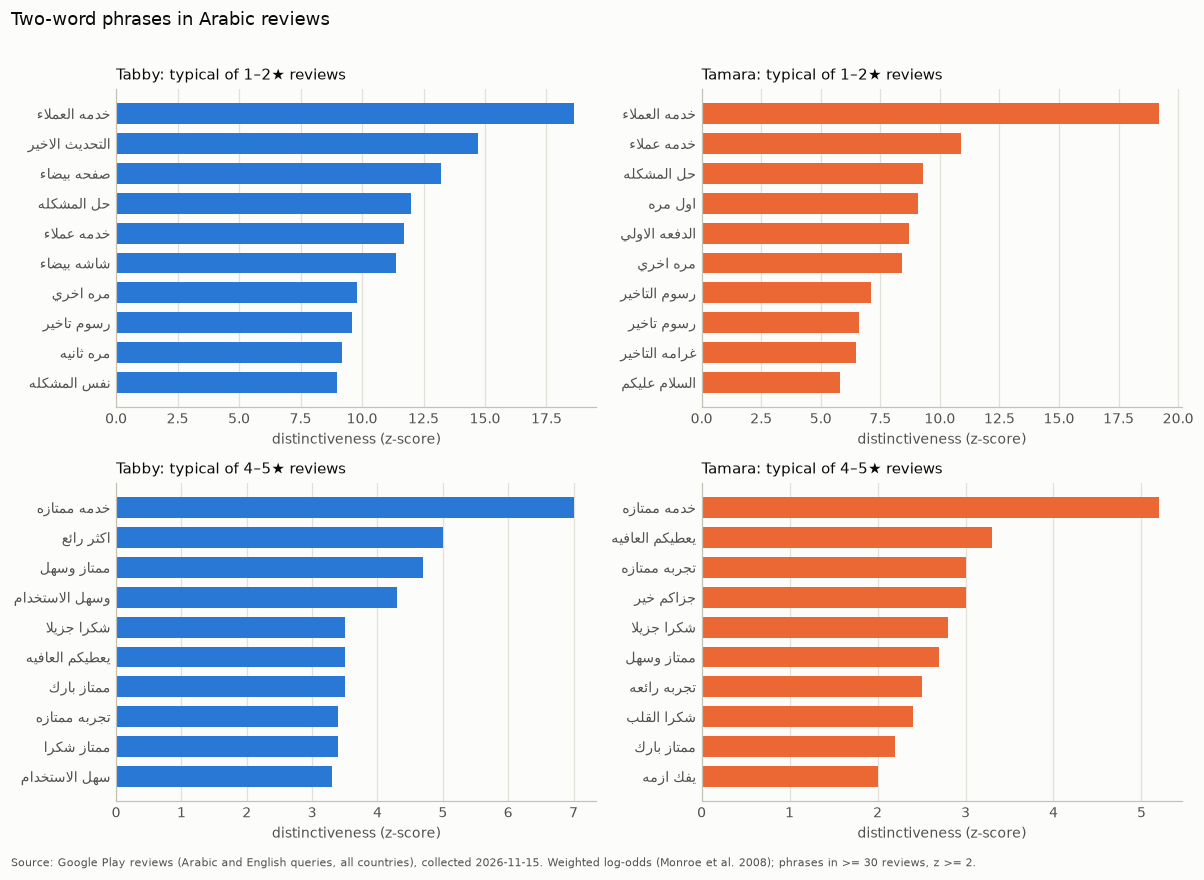

In [20]:
def terms_figure(script: str, name: str, title: str) -> plt.Figure:
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for col, app in enumerate(["tabby", "tamara"]):
        t = E.distinctive_terms(df, app, script, n=2, top_n=10)
        t = t[t["z"] >= 2]
        for row, side in enumerate(["negative", "positive"]):
            label = "1–2★" if side == "negative" else "4–5★"
            terms_panel(axes[row, col], t[t["side"] == side], app_color(app),
                        f"{app_name(app)}: typical of {label} reviews")
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    caption(fig, SOURCE_NOTE + " Weighted log-odds (Monroe et al. 2008); phrases in >= 30 reviews, z >= 2.")
    fig.tight_layout(rect=(0, 0.02, 1, 0.97))
    save(fig, name)
    return fig

terms_figure("arabic", "eda_terms_arabic", "Two-word phrases in Arabic reviews");

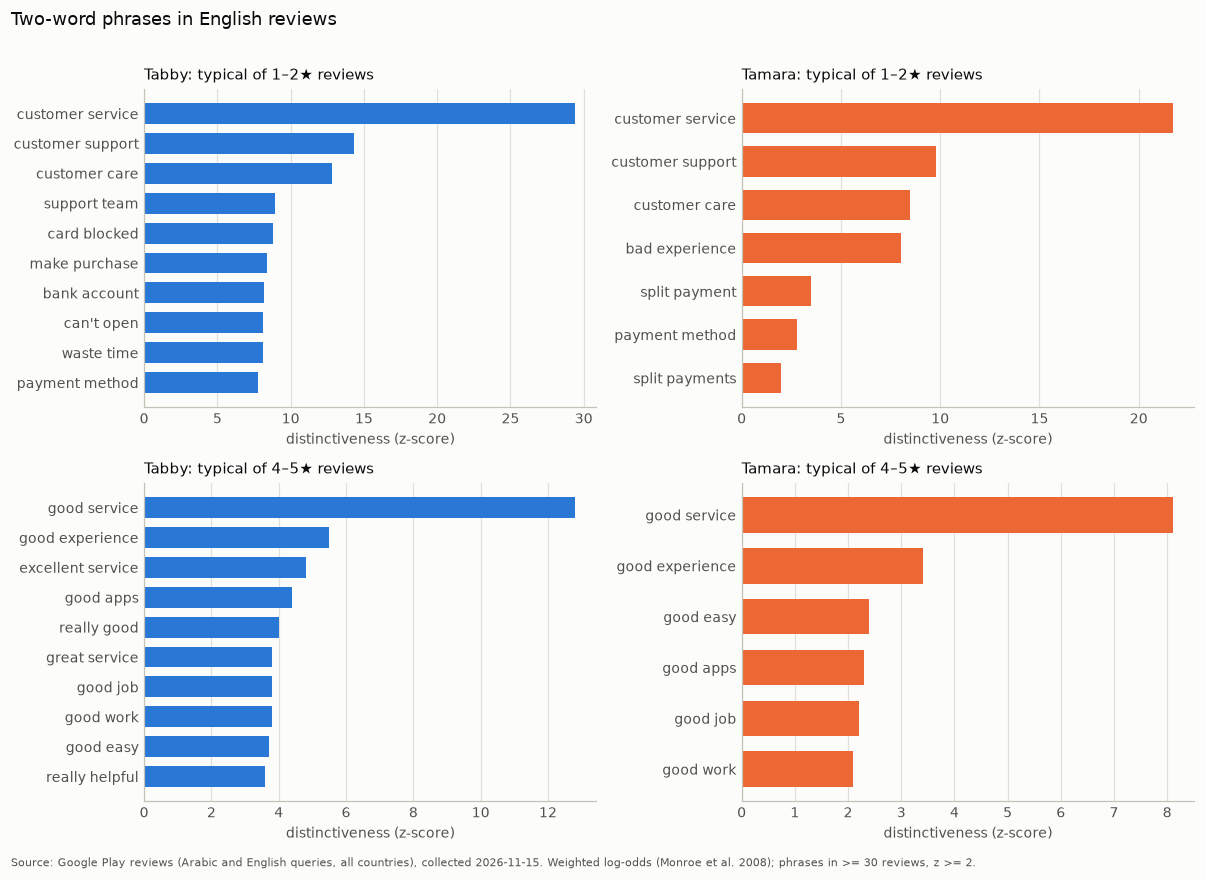

In [21]:
terms_figure("english", "eda_terms_english", "Two-word phrases in English reviews");

**How often?** Distinctive is not the same as frequent. The share of negative (1–2 star)
reviews that mention each complaint phrase (Arabic and English forms, listed in
`config.yaml`) shows that customer service comes up in about 8% of negative reviews for
both apps, and each of the other phrases in 2% or fewer. 85% of Tabby's white-screen mentions are from
July–August 2026 (section 5).

In [22]:
E.phrase_share(df).round(3)  # share of each app's 1-2 star reviews

app,tabby,tamara
customer_service,0.080,0.083
white_screen,0.020,0.001
late_fees,0.013,0.018
first_payment,0.004,0.010


## 9. Emoji

Emoji are kept as a feature. Negative reviews use different emoji, so they carry
sentiment signal even when the text is short.

In [23]:
pd.concat(
    {s: E.top_emojis(df, s, n=8).groupby("app")["emoji"].apply("".join) for s in ["negative", "positive"]},
    axis=1,
)

,negative,positive
app,,
tabby,👍👎😡😔😭😕😂👎🏻,👍❤️😊😍👌🥰💯🌹
tamara,👎👍😡👎🏻😔😭😞💔,👍❤️😊👌😍🥰🌹💯


## 10. Takeaways

| Finding | Consequence |
|---|---|
| 84% of reviews are 5 stars; positive reviews are ~2 words | Report macro-F1 and check class weighting for sentiment models; the gold set over-samples negative and neutral reviews |
| Reviews are not limited to one country: Arabic ones point mostly to Saudi Arabia, English ones mostly to the UAE | Use Arabic reviews as the Saudi stand-in when comparing with Saudi events and data |
| Tamara's positive reviews fell ~90% in Feb 2026, complaints only ~37% | Report complaint **counts** next to any share-based sentiment index, and flag Feb 2026 as a change in who reviews |
| Tabby negative spike Jul–Aug 2026, with most white-screen mentions | Look for a matching event when filling `events.csv` |
| Both apps reply to ~90% of complaints; Tabby also replies to positives since 2024 | Compare reply rates and times by rating and period, not overall |
| Customer service is the most common complaint phrase (~8% of negative reviews) | Starting topic list for topic modeling: customer service, app problems, fees, payments |
| Arabizi is absent; 52% / 38% of reviews are English | Models must handle Arabic **and** English; CAMeLBERT alone only covers Arabic |
| Emoji-only reviews (2.6%) | Kept for EDA, excluded from text-model training (`trainable = False`) |